# INF-8239 · U03.E05 · Motor recomendador reproducible (MovieLens)

Notebook de verificación. Consolida LAB08 y LAB09: auditoría, corte temporal, popularidad, contenido, factorización, híbrido, usuarios fríos y Pareto. Lee los artefactos de `reports/` y **recalcula** las cifras clave para comprobar que coinciden.

Requisito: `uv run python scripts/download_data.py` (MovieLens no se redistribuye en el repositorio).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import root_mean_squared_error

from inf8239_u03.config import MOVIELENS_DIR, ROOT
from inf8239_u03.data import load_movielens
from inf8239_u03.metrics import catalog_coverage, hit_rate_at_k
from inf8239_u03.recommenders import (ContentRecommender, GenreProfile, MatrixFactorization, hybrid_rerank,
                                      temporal_leave_one_out, weighted_popularity)

REPORTS = ROOT / 'reports'
pd.set_option('display.width', 160)
ratings, movies = load_movielens(MOVIELENS_DIR)
ratings.shape, movies.shape

((100836, 4), (9742, 3))

## 1. Auditoría
Se recalculan algunas cifras y se comparan con `reports/audit.json` (generado por `scripts/audit_data.py`).

In [2]:
audit = json.loads((REPORTS / 'audit.json').read_text(encoding='utf-8'))
density = len(ratings) / (ratings['userId'].nunique() * movies['movieId'].nunique())
assert np.isclose(density, audit['density'])
assert ratings.duplicated(['userId', 'movieId']).sum() == audit['duplicate_user_movie_pairs'] == 0
assert ratings.groupby('userId').size().min() == audit['ratings_per_user_min'] == 20
{k: audit[k] for k in ['ratings', 'users', 'movies_in_catalog', 'movies_without_ratings', 'density', 'nulls',
                       'first_rating', 'last_rating', 'movies_with_one_rating']}

{'ratings': 100836,
 'users': 610,
 'movies_in_catalog': 9742,
 'movies_without_ratings': 18,
 'density': 0.016968273253211548,
 'nulls': 0,
 'first_rating': '1996-03-29',
 'last_rating': '2018-09-24',
 'movies_with_one_rating': 3446}

## 2. Corte temporal
La última valoración de cada usuario va a prueba; ninguna valoración de entrenamiento es posterior a la de prueba del mismo usuario.

In [3]:
train, test = temporal_leave_one_out(ratings)
merged = test.merge(train.groupby('userId')['timestamp'].max().rename('last_train'), on='userId')
assert (merged['last_train'] <= merged['timestamp']).all()
evaluable = test[test['movieId'].isin(train['movieId'])]
print(f'train={len(train):,} test={len(test)} evaluables={len(evaluable)} (película de prueba vista en entrenamiento)')

train=100,226 test=610 evaluables=587 (película de prueba vista en entrenamiento)


## 3. Baseline de popularidad suavizada (LAB08)

In [4]:
weighted_popularity(ratings, movies).head(10)[['title', 'count', 'mean', 'weighted_score']].round(3)

,title,count,mean,weighted_score
movieId,,,,
318,"Shawshank Redemption, The (1994)",317,4.429,4.395
858,"Godfather, The (1972)",192,4.289,4.243
2959,Fight Club (1999),218,4.273,4.233
260,Star Wars: Episode IV - A New Hope (1977),251,4.231,4.198
50,"Usual Suspects, The (1995)",204,4.238,4.197
1221,"Godfather: Part II, The (1974)",129,4.260,4.195
527,Schindler's List (1993),220,4.225,4.188
1213,Goodfellas (1990),126,4.250,4.185
750,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.268,4.184


## 4. Recomendación por contenido: tres consultas de géneros distintos

In [5]:
content = ContentRecommender().fit(movies)
rows = []
for query in ['Toy Story (1995)', 'Godfather, The (1972)', 'Alien (1979)']:
    genres = movies.loc[movies['title'].eq(query), 'genres'].iloc[0]
    result = content.recommend(query, 10)
    assert query not in set(result['title'])
    rows.append({'consulta': query, 'géneros': genres, 'score=1.0 en Top-10': int((result['content_score'] == 1).sum()),
                 'películas del catálogo con géneros idénticos': int(movies['genres'].eq(genres).sum()) - 1})
pd.DataFrame(rows)

,consulta,géneros,score=1.0 en Top-10,películas del catálogo con géneros idénticos
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,10,12
1,"Godfather, The (1972)",Crime|Drama,10,133
2,Alien (1979),Horror|Sci-Fi,10,52


Todas las posiciones empatan en 1.0: el Top-10 es una elección arbitraria entre las películas con la misma combinación de géneros (sobre-especialización).

## 5. Baselines y tabla de Pareto (LAB09, tres semillas)

In [6]:
pd.read_csv(REPORTS / 'baselines.csv').round(4)

,method,rmse,hit_rate_at_10,precision_at_10,catalog_coverage,distinct_genres
0,Media global (ratings),1.1157,NaN,NaN,NaN,NaN
1,Media por película (ratings),1.0503,NaN,NaN,NaN,NaN
2,"Popularidad (cantidad, media)",NaN,0.0426,0.0043,0.0122,11.6388
3,Contenido puro (perfil de géneros),NaN,0.0017,0.0002,0.0778,5.9710


In [7]:
pareto = pd.read_csv(REPORTS / 'pareto.csv')
pareto.round(4)

,factors,alpha,hit_rate_mean,hit_rate_std,coverage_mean,coverage_std,distinct_genres,rmse_mean,train_seconds_mean,model_bytes,dominated
0,10,0.00,0.0256,0.0017,0.0899,0.0009,7.4656,1.0333,31.5173,824880,False
1,10,0.25,0.0256,0.0034,0.0827,0.0015,8.0954,1.0333,31.5173,824880,True
2,10,0.50,0.0307,0.0034,0.0656,0.0013,9.6985,1.0333,31.5173,824880,False
3,10,0.75,0.0375,0.0104,0.0558,0.0017,10.7535,1.0333,31.5173,824880,False
4,10,1.00,0.0346,0.0094,0.0539,0.0012,11.0505,1.0333,31.5173,824880,True
5,20,0.00,0.0273,0.0030,0.1092,0.0047,7.3083,1.0256,24.1494,1649760,False
6,20,0.25,0.0290,0.0059,0.1005,0.0052,7.8717,1.0256,24.1494,1649760,False
7,20,0.50,0.0318,0.0052,0.0845,0.0041,9.5923,1.0256,24.1494,1649760,False
8,20,0.75,0.0318,0.0049,0.0737,0.0038,10.7104,1.0256,24.1494,1649760,True
9,20,1.00,0.0307,0.0061,0.0709,0.0036,11.1283,1.0256,24.1494,1649760,True


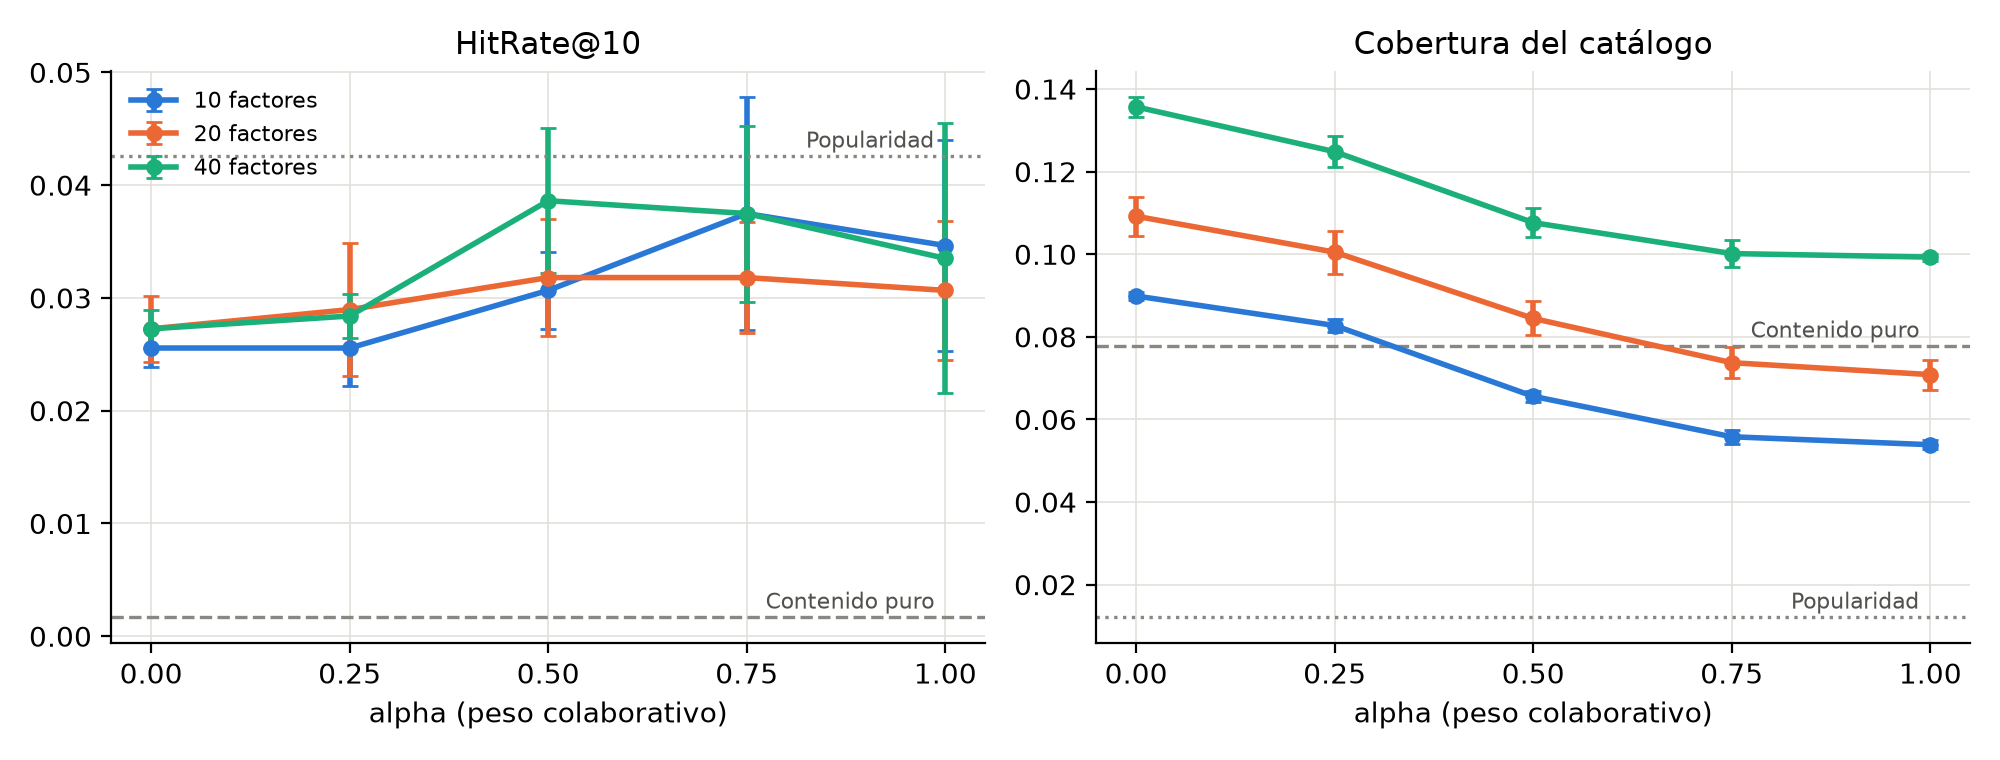

In [8]:
display(Image(filename=str(REPORTS / 'figures/alpha_tradeoff.png'), width=900))

## 6. Verificación: reentrenar la configuración elegida (40 factores, semilla 42, alpha 0.5)

In [9]:
model = MatrixFactorization(factors=40, seed=42).fit(train, epochs=12)
rmse = root_mean_squared_error(evaluable['rating'], [model.predict(r.userId, r.movieId) for r in evaluable.itertuples()])
profile = GenreProfile().fit(movies)
recs = {}
for user in evaluable['userId']:
    history = train.loc[train['userId'].eq(user), ['movieId', 'rating']]
    pool = model.top_n(user, set(history['movieId']), 100)
    recs[int(user)] = hybrid_rerank(pool, profile.scores(profile.profile(history), pool['movieId']), 0.5)['movieId'].astype(int).tolist()
reported = pd.read_csv(REPORTS / 'experiments.csv').query('factors == 40 and seed == 42 and alpha == 0.5').iloc[0]
check = pd.DataFrame({'recalculado': [rmse, hit_rate_at_k(recs, evaluable, 10), catalog_coverage(recs, len(model.items))],
                      'reportado': [reported['rmse'], reported['hit_rate_at_10'], reported['catalog_coverage']]},
                     index=['RMSE', 'HitRate@10', 'Cobertura'])
assert np.allclose(check['recalculado'], check['reportado'])
check

,recalculado,reportado
RMSE,1.021052,1.021052
HitRate@10,0.035775,0.035775
Cobertura,0.106793,0.106793


## 7. Tres perfiles

In [10]:
print(json.dumps(json.loads((REPORTS / 'profiles_checks.json').read_text(encoding='utf-8')), indent=1))
pd.read_csv(REPORTS / 'profiles.csv')[['profile', 'userId', 'rank', 'title', 'genres', 'hybrid', 'source']]

{
 "config": {
  "factors": 40,
  "epochs": 12,
  "alpha": 0.5,
  "seeds": [
   42,
   123,
   2026
  ]
 },
 "wide": {
  "userId": 414,
  "train_ratings": 2697,
  "seen_in_list": 0,
  "overlap_with_alpha_1": 4,
  "overlap_with_alpha_0": 4,
  "mean_jaccard_across_seeds": 0.5384615384615384
 },
 "small": {
  "userId": 53,
  "train_ratings": 19,
  "seen_in_list": 0,
  "overlap_with_alpha_1": 7,
  "overlap_with_alpha_0": 4,
  "mean_jaccard_across_seeds": 0.017543859649122806
 },
 "new": {
  "userId": 611,
  "train_ratings": 0,
  "collaborative_rows": 0,
  "fallback_items": 10
 }
}


,profile,userId,rank,title,genres,hybrid,source
0,wide,414,1,12 Angry Men (1957),Drama,0.910,híbrido personalizado
1,wide,414,2,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,0.787,híbrido personalizado
2,wide,414,3,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,0.719,híbrido personalizado
3,wide,414,4,Intouchables (2011),Comedy|Drama,0.674,híbrido personalizado
4,wide,414,5,Manhattan (1979),Comedy|Drama|Romance,0.645,híbrido personalizado
5,wide,414,6,High Heels (Tacones lejanos) (1991),Comedy|Drama,0.605,híbrido personalizado
6,wide,414,7,Annie Hall (1977),Comedy|Romance,0.599,híbrido personalizado
7,wide,414,8,All About Eve (1950),Drama,0.569,híbrido personalizado
8,wide,414,9,"Lives of Others, The (Das leben der Anderen) (...",Drama|Romance|Thriller,0.569,híbrido personalizado
9,wide,414,10,Secrets & Lies (1996),Drama,0.554,híbrido personalizado


## 8. Conclusión
- **Ratings:** la factorización (RMSE 1.016–1.037) mejora a la media global (1.116) y a la media por película (1.050).
- **Ranking:** la popularidad obtiene el mayor HitRate@10 (0.043) pero solo cubre el 1.2 % del catálogo y no personaliza; el contenido puro casi no acierta (0.002).
- **Híbrido:** 40 factores con alpha 0.5 no está dominado y combina HitRate@10 de 0.039 con 10.8 % de cobertura. Las diferencias de HitRate entre configuraciones son de pocos usuarios (13 a 29 aciertos de 587) y caben en la variación entre semillas.
- **Usuarios fríos:** el usuario nuevo recibe el fallback de popularidad, declarado como no personalizado; con 19 valoraciones la lista cambia casi por completo entre semillas.